## Telco Customer Churn Prediction

## Artificial neural network

This notebook builds a binary classifier to estimate whether a telecom customer will leave. It uses the cleaned, one-hot encoded data exported by the EDA notebook. 


## 1. Load the prepared data

The target is `Churn` (`1` means the customer left; `0` means the customer stayed). The CSV includes an index column from export, which is removed. We select the target by its column name so it cannot accidentally remain among the model inputs.

In [13]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)

df = pd.read_csv("tel_churn.csv")
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

X = df.drop(columns="Churn").astype("float32")
y = df["Churn"].astype("int32")
feature_columns = X.columns.tolist()

print(f"Rows: {len(df):,}")
print(f"Input features: {X.shape[1]}")
print(f"Churn rate: {y.mean():.1%}")
print("Churn column included in inputs:", "Churn" in X.columns)

Rows: 7,032
Input features: 50
Churn rate: 26.6%
Churn column included in inputs: False


## 2. Create train, validation, and test sets

The split is stratified so each set has a similar churn proportion. The validation set is used for early stopping and threshold selection. The test set is used only for the final evaluation.

In [14]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20, random_state=RANDOM_STATE, stratify=y_train_full
)

print(f"Training rows:   {len(X_train):,}")
print(f"Validation rows: {len(X_val):,}")
print(f"Test rows:       {len(X_test):,}")

Training rows:   4,500
Validation rows: 1,125
Test rows:       1,407


## 3. Scale continuous inputs

The one-hot columns are already on a 0/1 scale. Standardize only the two charge amounts. The scaler learns its means and standard deviations from the training split; validation and test data use those same values.

In [15]:
numeric_columns = ["MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_val[numeric_columns] = scaler.transform(X_val[numeric_columns])
X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])

## 4. Train the ANN

This is a small feed-forward network suited to the size of this dataset. I am not applying class weights in this run because the current objective is overall accuracy; class weighting can improve churn recall while lowering accuracy. The validation ROC AUC controls early stopping so training stops when the ranking quality stops improving.

In [16]:
model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.15),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(curve="PR", name="pr_auc"),
    ],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_roc_auc",
    mode="max",
    patience=12,
    restore_best_weights=True,
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1,
)

best_epoch = int(np.argmax(history.history["val_roc_auc"]) + 1)
print(f"Best validation ROC AUC: {max(history.history['val_roc_auc']):.3f}")
print(f"Best epoch: {best_epoch} of {len(history.history['loss'])}")

Epoch 1/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7104 - loss: 0.5155 - pr_auc: 0.4017 - roc_auc: 0.7257 - val_accuracy: 0.7760 - val_loss: 0.4515 - val_pr_auc: 0.6053 - val_roc_auc: 0.8223
Epoch 2/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7736 - loss: 0.4526 - pr_auc: 0.5632 - roc_auc: 0.8140 - val_accuracy: 0.7831 - val_loss: 0.4412 - val_pr_auc: 0.6442 - val_roc_auc: 0.8297
Epoch 3/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7878 - loss: 0.4347 - pr_auc: 0.6136 - roc_auc: 0.8311 - val_accuracy: 0.7964 - val_loss: 0.4375 - val_pr_auc: 0.6502 - val_roc_auc: 0.8312
Epoch 4/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8038 - loss: 0.4294 - pr_auc: 0.6175 - roc_auc: 0.8373 - val_accuracy: 0.7911 - val_loss: 0.4381 - val_pr_auc: 0.6499 - val_roc_auc: 0.8302
Epoch 5/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7953 - loss: 0.4288 - pr_auc: 0.6171 - roc_auc: 0.8360 - val_accuracy: 0.7956 - val_loss: 0.4369 - val_pr

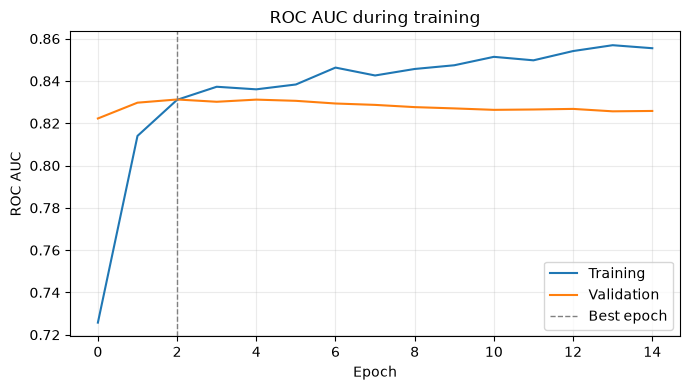

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history.history["roc_auc"], label="Training")
ax.plot(history.history["val_roc_auc"], label="Validation")
ax.axvline(best_epoch - 1, color="gray", linestyle="--", linewidth=1, label="Best epoch")
ax.set(title="ROC AUC during training", xlabel="Epoch", ylabel="ROC AUC")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Train and Compare a Decision Tree

In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, precision_score, recall_score

# Limit the tree's size to reduce overfitting.
tree_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    random_state=42,
)
tree_model.fit(X_train, y_train)

# Get validation probabilities from both models.
ann_val_prob = model.predict(X_val, verbose=0).ravel()
tree_val_prob = tree_model.predict_proba(X_val)[:, 1]

# Compare both models at the same threshold.
ann_val_pred = (ann_val_prob >= 0.50).astype("int32")
tree_val_pred = (tree_val_prob >= 0.50).astype("int32")

comparison = pd.DataFrame([
    {
        "Model": "ANN",
        "Accuracy": accuracy_score(y_val, ann_val_pred),
        "Churn precision": precision_score(y_val, ann_val_pred, zero_division=0),
        "Churn recall": recall_score(y_val, ann_val_pred, zero_division=0),
        "Churn F1": f1_score(y_val, ann_val_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_val, ann_val_prob),
        "PR AUC": average_precision_score(y_val, ann_val_prob),
    },
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_val, tree_val_pred),
        "Churn precision": precision_score(y_val, tree_val_pred, zero_division=0),
        "Churn recall": recall_score(y_val, tree_val_pred, zero_division=0),
        "Churn F1": f1_score(y_val, tree_val_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_val, tree_val_prob),
        "PR AUC": average_precision_score(y_val, tree_val_prob),
    },
]).set_index("Model")

comparison.round(3)

,Accuracy,Churn precision,Churn recall,Churn F1,ROC AUC,PR AUC
Model,,,,,,
ANN,0.796,0.656,0.492,0.562,0.831,0.650
Decision Tree,0.775,0.584,0.535,0.558,0.809,0.585


In [19]:
print("Decision Tree validation confusion matrix:")
print(confusion_matrix(y_val, tree_val_pred, labels=[0, 1]))

print("\nDecision Tree validation classification report:")
print(classification_report(
    y_val,
    tree_val_pred,
    labels=[0, 1],
    target_names=["No churn", "Churn"],
    zero_division=0,
))

Decision Tree validation confusion matrix:
[[712 114]
 [139 160]]

Decision Tree validation classification report:
              precision    recall  f1-score   support

    No churn       0.84      0.86      0.85       826
       Churn       0.58      0.54      0.56       299

    accuracy                           0.78      1125
   macro avg       0.71      0.70      0.70      1125
weighted avg       0.77      0.78      0.77      1125



## 6. Select a decision threshold on validation data

A sigmoid output is a probability; converting it to a class requires a threshold. The usual 0.50 is only a default. Since this run is focused on accuracy, choose the threshold that gives the highest validation accuracy. This choice is made without looking at test labels.

In [20]:
val_prob = model.predict(X_val, verbose=0).ravel()
threshold_candidates = np.linspace(0.10, 0.90, 161)
validation_accuracies = [
    accuracy_score(y_val, val_prob >= candidate)
    for candidate in threshold_candidates
]
best_index = int(np.argmax(validation_accuracies))
threshold = float(threshold_candidates[best_index])
val_pred = (val_prob >= threshold).astype("int32")

print(f"Selected threshold: {threshold:.3f}")
print(f"Validation accuracy: {accuracy_score(y_val, val_pred):.3f}")
print(classification_report(
    y_val, val_pred, labels=[0, 1], target_names=["No churn", "Churn"], zero_division=0
))

Selected threshold: 0.500
Validation accuracy: 0.796
              precision    recall  f1-score   support

    No churn       0.83      0.91      0.87       826
       Churn       0.66      0.49      0.56       299

    accuracy                           0.80      1125
   macro avg       0.74      0.70      0.71      1125
weighted avg       0.78      0.80      0.79      1125



## 7. Final test-set evaluation

The test set is evaluated after the model and threshold are chosen. Accuracy is shown alongside churn precision, recall, and F1 so the class imbalance is visible. In the confusion matrix, rows are actual labels and columns are predicted labels.

Majority-class baseline accuracy: 0.734
ANN test accuracy:                0.792
Test ROC AUC:                     0.831
Test PR AUC:                      0.605

              precision    recall  f1-score   support

    No churn       0.83      0.90      0.86      1033
       Churn       0.64      0.49      0.55       374

    accuracy                           0.79      1407
   macro avg       0.74      0.69      0.71      1407
weighted avg       0.78      0.79      0.78      1407



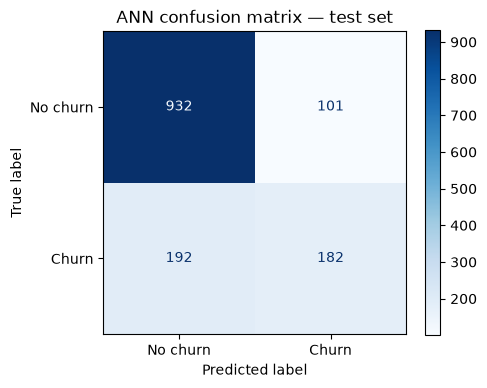

In [21]:
test_prob = model.predict(X_test, verbose=0).ravel()
test_pred = (test_prob >= threshold).astype("int32")

majority_baseline = float((y_test == 0).mean())
print(f"Majority-class baseline accuracy: {majority_baseline:.3f}")
print(f"ANN test accuracy:                {accuracy_score(y_test, test_pred):.3f}")
print(f"Test ROC AUC:                     {roc_auc_score(y_test, test_prob):.3f}")
print(f"Test PR AUC:                      {average_precision_score(y_test, test_prob):.3f}")
print()
print(classification_report(
    y_test, test_pred, labels=[0, 1], target_names=["No churn", "Churn"], zero_division=0
))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    labels=[0, 1],
    display_labels=["No churn", "Churn"],
    values_format="d",
    cmap="Blues",
    ax=ax,
)
ax.set_title("ANN confusion matrix — test set")
plt.tight_layout()
plt.show()

## 8. Save the model and preprocessing

The scaler, feature order, and selected threshold are part of the prediction workflow. Keep them with the saved ANN so future inputs can be transformed in the same way.

In [22]:
artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(exist_ok=True)

model.save(artifacts_dir / "churn_ann.keras")
joblib.dump(scaler, artifacts_dir / "charge_scaler.joblib")
joblib.dump(feature_columns, artifacts_dir / "feature_columns.joblib")
(artifacts_dir / "decision_threshold.json").write_text(
    json.dumps({"threshold": threshold}, indent=2),
    encoding="utf-8",
)

print(f"Saved model and preprocessing files to: {artifacts_dir.resolve()}")

Saved model and preprocessing files to: C:\Project\ann-based-customer-churn-prediction\artifacts
